# Time-series + snapshot transformer: demo of the recommended early-fusion design

This notebook is the end-to-end counterpart of `01_demo_late_fusion_cls.ipynb`, for the design recommended in `02_alternative_value_aware_tokens.ipynb`. Missing and special values are **not** encoded by a separate branch. Their learned embeddings go **into the same tokens** as the regular values, so one encoder attends over observed and unobserved cells together.

```
late fusion  (01):  head([CLS_regular , CLS_missing/special , CLS_snapshot])
early fusion (03):  head([CLS_time-series , CLS_snapshot])          <- this notebook
```

| Section | Content |
|---|---|
| 1 | Data as delivered: time-series frame, missing and special indicator frames, PLE snapshot frame, target |
| 2 | From DataFrames to aligned arrays |
| 3 | Special-value treatment: one state code per cell, statistics on regular cells only, re-imputation |
| 4 | Tokenizer: sliding patches **plus value-aware cell embeddings** (the key difference) |
| 5 | Model: one factorized time-series encoder with a 2-D CLS grid, plus the snapshot encoder and head |
| 6 | Training with **MSE**: per-epoch metrics, logs, checkpoints, early stopping, best model by validation RMSE |
| 7 | Training with **Tweedie** loss and tuning the power `p` |
| 8 | Reloading the best checkpoint, then predicting and evaluating |
| 9 | What the model learned about missing and special values (state-embedding geometry) |
| 10 | Side-by-side with the late-fusion runs from notebook 01 (if they exist) |
| 11 | Checklist for running on your data |

The data is the same synthetic set as in notebook 01: same seed, same split, same preprocessing, same training settings. Only `missing_fusion` changes, so the results can be compared directly.

### Architecture

```
x      (B, T=11, V) ─┐
state  (B, T, V)    ─┴─► sliding patches per variable: values (B,V,Np,P) + states (B,V,Np,P)
                          │
                          ▼   for every cell of a patch:
                          e(v,t) = 1[regular]·(w·x + b)  +  E_state[state]      (E_state shared by ALL variables)
                          concat the P cell vectors ─► linear ─► patch token (d_model)
                          │
          ┌──────────── 2-D token grid with CLS row / column ─────────────┐
          │ [CLS global] [CLS t1] ... [CLS tNp]                            │   L × (attention across variables
          │ [CLS var1 ]  p(1,1)  ...  p(1,Np)                              │        ─► attention across time
          │   ...                                                          │        ─► FFN)
          │ [CLS varV ]  p(V,1)  ...  p(V,Np)                              │
          └────────────────────────────────────────────────────────────────┘ ─► CLS_time-series
snapshot PLE (B, S, bins) ─► per-variable linear embedding ─► [CLS] + S tokens ─► transformer ─► CLS_snapshot

head( concat[ CLS_time-series , CLS_snapshot ] ) ─► ŷ
```

Requirements that still hold:
* sliding patches per variable;
* **one embedding for "missing" and one per special value**, shared by every variable;
* attention across variables first, then across time, read out through a BERT-style CLS;
* late fusion of the snapshot CLS;
* MSE and Tweedie losses, per-epoch metrics and checkpoints, early stopping.

In [1]:
import sys, os, math, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from tsfusion import (ModelConfig, TrainConfig, RawData, Preprocessor, Trainer, TSFusionTransformer,
                      long_df_to_array, group_columns_by_prefix, build_state, default_target_mode,
                      load_checkpoint, predict_with, regression_metrics, count_parameters,
                      tweedie_deviance)
from tsfusion.model import SlidingPatcher
from tsfusion.synthetic import make_synthetic_dataset

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if HAS_GPU else "cpu"   # ONE GPU (pick another with "cuda:1" or CUDA_VISIBLE_DEVICES)
print("torch", torch.__version__, "| CUDA:", HAS_GPU, "|", torch.cuda.get_device_name(0) if HAS_GPU else "CPU only")

RUNS = REPO / "runs" / "demo_early_fusion"
LATE_RUNS = REPO / "runs" / "demo_late_fusion"        # written by notebook 01 (used in section 10)
SMALL = not HAS_GPU                                   # CPU-friendly sizes; larger on a GPU
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

torch 2.15.0+cu132 | CUDA: False | CPU only


## 1. Data as delivered

The inputs are identical to notebook 01:

| object | layout | notes |
|---|---|---|
| `ts_df` | long: index `(record_id, time_step)`, one column per variable | missing cells **imputed as 0**; special cells hold a sentinel (here -999/-998/-997) |
| `missing_df` | same layout, 0/1 | 1 = the value was missing |
| `special_df` | same layout, integer code | 0 = not special, `k` = special value `k`; each code means the same thing for every variable |
| `snapshot_ple_df` | one row per record, columns `<feature>_bin<j>` | piecewise linear encoding of each snapshot variable (bins fitted on train) |
| `y` | one value per record | positive, right-skewed, a few extreme values |

Replace this cell with your own loading code; nothing downstream changes.

In [2]:
data = make_synthetic_dataset(n_records=6000, n_vars=8, n_special_codes=3, seed=0)
ts_df, missing_df, special_df = data["ts_df"], data["missing_df"], data["special_df"]
snapshot_ple_df, snapshot_raw_df, y = data["snapshot_ple_df"], data["snapshot_raw_df"], data["y"]
train_ids, val_ids = data["train_ids"], data["val_ids"]          # your existing split
var_names, time_steps = data["var_names"], data["time_steps"]
N_SPECIAL = data["n_special_codes"]

print(f"ts_df        {ts_df.shape}  = ({ts_df.index.get_level_values(0).nunique()} records x "
      f"{ts_df.index.get_level_values(1).nunique()} steps, {ts_df.shape[1]} variables)")
print(f"missing_df   {missing_df.shape}   special_df {special_df.shape}")
print(f"snapshot_ple {snapshot_ple_df.shape}   y {y.shape}   train {len(train_ids)}  val {len(val_ids)}")
print("special sentinels -> code:", data["special_sentinels"])
ts_df.head(11).round(1)

ts_df        (66000, 8)  = (6000 records x 11 steps, 8 variables)
missing_df   (66000, 8)   special_df (66000, 8)
snapshot_ple (6000, 42)   y (6000,)   train 4800  val 1200
special sentinels -> code: {-999.0: 3, -998.0: 2, -997.0: 1}


var_00  var_01  var_02  var_03  var_04  var_05  var_06  var_07
record_id time_step                                                                
100000    1          -189.7   368.7  -997.0  -340.7   118.2   747.6     0.0   425.6
          2          -475.5   204.4   -87.4  -159.9   284.2   657.7     0.0     0.0
          3          -554.4   343.1    68.1  -125.1   249.8   562.6     0.0   420.2
          4          -544.5   259.6   109.6  -159.9   296.9   668.2     0.0   447.1
          5             0.0   184.6   462.7  -209.6     0.0   559.3     0.0   445.8
          6          -109.4   190.1   183.5  -296.2   241.9   761.3     0.0   449.2
          7            21.2   191.9   202.5  -220.7   190.2   823.4     0.0   447.6
          8           -21.6   319.4   219.4  -216.9   190.1   815.0     0.0   441.0
          9           150.0   273.1   311.7  -342.1   201.9   718.9     0.0   446.6
          10          212.9   347.3   558.3  -233.5   289.3   722.2  -455.9   451.1
          11          317.2   149.9   566.6   -91.9   182.2     0.0  -496.5   423.5

One record with both missing and special cells. The three frames are aligned cell by cell:

In [3]:
rid = next(r for r in train_ids
           if missing_df.loc[r].values.sum() >= 3 and special_df.loc[r].values.sum() >= 2)
pd.concat({"value": ts_df.loc[rid].round(1), "missing": missing_df.loc[rid],
           "special": special_df.loc[rid]}, axis=1).iloc[:, [0, 1, 2, 8, 9, 10, 16, 17, 18]]

value               missing               special              
          var_00 var_01 var_02  var_00 var_01 var_02  var_00 var_01 var_02
time_step                                                                 
1            0.0  243.2  201.7       1      0      0       0      0      0
2         -175.8  164.3  280.3       0      0      0       0      0      0
3         -285.8  326.8  462.1       0      0      0       0      0      0
4         -226.2  155.6  487.4       0      0      0       0      0      0
5         -384.6  166.0  519.5       0      0      0       0      0      0
6          -84.1  223.1  601.4       0      0      0       0      0      0
7           67.6  389.5  433.3       0      0      0       0      0      0
8          211.7 -998.0  493.4       0      0      0       0      2      0
9           26.9  427.7  351.1       0      0      0       0      0      0
10          96.5  408.4  489.5       0      0      0       0      0      0
11         -14.8  505.3  427.2       0      0      0       0      0      0

snapshot features and #bins: {'age': 8, 'income': 10, 'tenure_m': 6, 'score': 10, 'utilization': 8}
count      6000.0
mean       2719.8
std        5317.9
min           4.8
50%        1173.6
90%        6154.6
99%       22640.7
99.9%     58097.8
max      120448.1
skewness = 7.9   max/median = 103x   min = 4.85 (> 0)


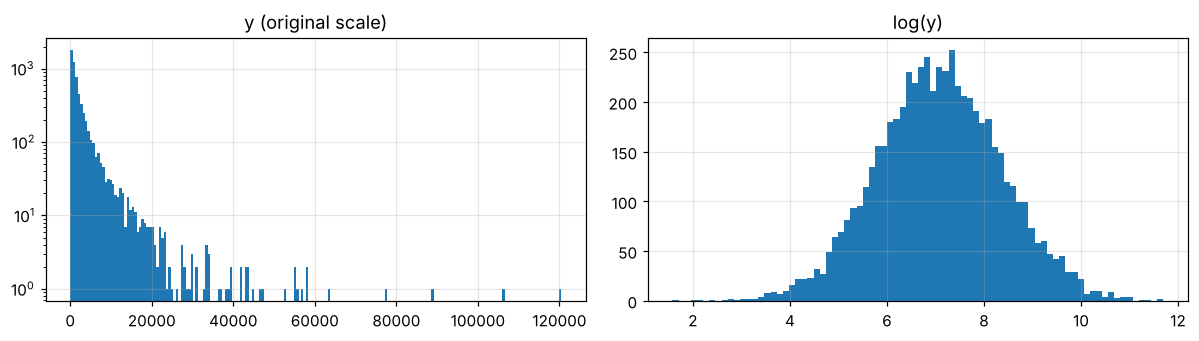

In [4]:
ple_groups = group_columns_by_prefix(snapshot_ple_df.columns)       # [(feature, [cols...]), ...]
ple_cols = [c for _, cols in ple_groups for c in cols]               # ALWAYS use this column order
group_sizes = [len(cols) for _, cols in ple_groups]
print("snapshot features and #bins:", {name: len(cols) for name, cols in ple_groups})

print(y.describe(percentiles=[.5, .9, .99, .999]).round(1).to_string())
print(f"skewness = {y.skew():.1f}   max/median = {y.max() / y.median():.0f}x   min = {y.min():.2f} (> 0)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(y, bins=200); ax[0].set_title("y (original scale)"); ax[0].set_yscale("log")
ax[1].hist(np.log(y), bins=80); ax[1].set_title("log(y)")
plt.tight_layout(); plt.show()

## 2. From DataFrames to arrays

The model consumes these aligned arrays, all built in the **same record order**:

| array | shape | dtype |
|---|---|---|
| `x` | `(N, T, V)` | float32 |
| `missing` | `(N, T, V)` | 0/1 |
| `special` | `(N, T, V)` | int, 0..K |
| `snapshot` | `(N, Σ bins)` | float32 |
| `y` | `(N,)` | float |

In [5]:
def to_raw(ids) -> RawData:
    kw = dict(value_cols=var_names, record_ids=ids, time_steps=time_steps)
    x, _ = long_df_to_array(ts_df, **kw)
    miss, _ = long_df_to_array(missing_df, fill_value=1, **kw)
    spec, _ = long_df_to_array(special_df, fill_value=0, **kw)
    return RawData(x=x, missing=miss, special=spec.astype(np.int64),
                   snapshot=snapshot_ple_df.loc[ids, ple_cols].to_numpy(),
                   y=y.loc[ids].to_numpy())

train_raw, val_raw = to_raw(train_ids), to_raw(val_ids)
pd.DataFrame({k: [getattr(train_raw, k).shape, getattr(val_raw, k).shape, getattr(train_raw, k).dtype]
              for k in ["x", "missing", "special", "snapshot", "y"]},
             index=["train", "validation", "dtype"])

,x,missing,special,snapshot,y
train,"(4800, 11, 8)","(4800, 11, 8)","(4800, 11, 8)","(4800, 42)","(4800,)"
validation,"(1200, 11, 8)","(1200, 11, 8)","(1200, 11, 8)","(1200, 42)","(1200,)"
dtype,float32,float32,int64,float32,float64


## 3. Special-value treatment

The preprocessing is the same as in notebook 01. It is fitted on the training split only.

| state | meaning |
|---|---|
| 0 | regular (observed) value |
| 1 | missing |
| 1 + k | special value k (k = 1..K) |

1. Missing and special flags merge into one `state` per cell. A cell flagged as both counts as special, and a NaN in `x` counts as missing.
2. The per-variable mean and std are computed on **regular cells only**, so sentinels and imputed zeros do not distort them.
3. Values are standardised and clipped to ±10, and every non-regular cell is set to exactly 0.
4. The target transform follows the loss: `standard` for MSE, `y / mean(y)` for Tweedie.

**What changes with early fusion.** In late fusion the regular branch sees a "hole" (0 plus an "is regular" bit), and a *separate* branch encodes the states. Here the 0 in a non-regular cell is **never read**: the cell's embedding is replaced by the learned embedding of its state, inside the same token as the neighbouring regular values.

share of cells by state (%):
regular             84.75
missing             12.41
special 2 (-998)     1.13
special 1 (-997)     0.86
special 3 (-999)     0.85


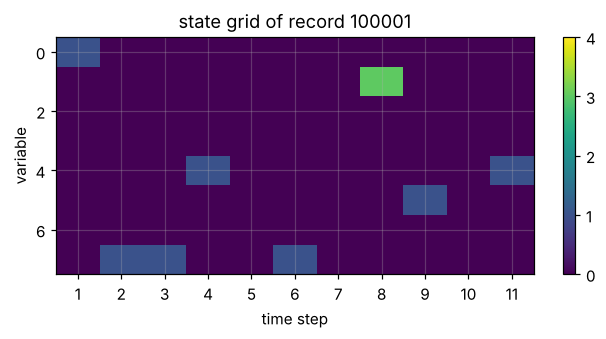

In [6]:
state_tr = build_state(train_raw.missing, train_raw.special)
names = {0: "regular", 1: "missing", **{1 + k: f"special {k} ({s:.0f})"
         for s, k in data["special_sentinels"].items()}}
share = pd.Series(state_tr.ravel()).map(names).value_counts(normalize=True).mul(100).round(2)
print("share of cells by state (%):"); print(share.to_string())

rec = list(train_ids).index(rid)
fig, ax = plt.subplots(figsize=(7, 2.8))
im = ax.imshow(state_tr[rec].T, cmap="viridis", vmin=0, vmax=1 + N_SPECIAL, aspect="auto")
ax.set_xlabel("time step"); ax.set_ylabel("variable"); ax.set_xticks(range(11), time_steps)
ax.set_title(f"state grid of record {rid}"); plt.colorbar(im, ticks=range(2 + N_SPECIAL)); plt.show()

In [7]:
prep_mse = Preprocessor(n_special_codes=N_SPECIAL, snapshot_group_sizes=group_sizes,
                        snapshot_kind="ple", target_mode=default_target_mode("mse")).fit(train_raw)
train_mse, val_mse = prep_mse.transform(train_raw), prep_mse.transform(val_raw)

print("x       ", tuple(train_mse.x.shape), train_mse.x.dtype)
print("state   ", tuple(train_mse.state.shape), train_mse.state.dtype, "values", torch.unique(train_mse.state).tolist())
print("snapshot", tuple(train_mse.snapshot.shape), "(N, S snapshot vars, max bins)")
print("y       ", tuple(train_mse.y.shape), "transformed; y_raw kept for metrics")
print("all non-regular cells are 0:", bool((train_mse.x[train_mse.state != 0] == 0).all()))
pd.DataFrame(train_mse.x[rec].numpy(), index=time_steps, columns=var_names).round(2).T

x        (4800, 11, 8) torch.float32
state    (4800, 11, 8) torch.uint8 values [0, 1, 2, 3, 4]
snapshot (4800, 5, 10) (N, S snapshot vars, max bins)
y        (4800,) transformed; y_raw kept for metrics
all non-regular cells are 0: True


,1,2,3,4,5,6,7,8,9,10,11
var_00,0.00,-0.41,-0.62,-0.50,-0.81,-0.23,0.06,0.34,-0.02,0.12,-0.10
var_01,-0.80,-1.12,-0.46,-1.15,-1.11,-0.88,-0.20,0.00,-0.05,-0.13,0.27
var_02,-0.88,-0.72,-0.36,-0.31,-0.24,-0.08,-0.42,-0.29,-0.58,-0.30,-0.43
var_03,-0.42,-0.29,-0.43,-0.67,-0.91,-0.80,-0.78,-0.66,-0.59,-0.91,-1.02
var_04,-0.62,-0.60,-0.55,0.00,-0.05,-0.18,-0.49,-0.20,-0.50,0.49,0.00
var_05,-0.06,-0.35,-0.13,-0.28,-0.19,-0.04,0.04,-0.15,0.00,-0.01,-0.02
var_06,-0.58,-0.79,-0.58,-0.55,-0.31,0.09,-0.26,-0.36,-0.65,-0.40,-0.55
var_07,-0.61,0.00,0.00,0.10,0.40,0.00,0.16,0.23,-0.40,-0.49,-0.13


## 4. Tokenizer: sliding patches with value-aware cells

**4.1 Sliding patches.** These work exactly as in notebook 01: windows of `patch_len` steps, moving `patch_stride` steps each time, cut per variable and applied to both values and states. Right-padding keeps the latest step covered.

In [8]:
P, S = 3, 1
patcher = SlidingPatcher(n_steps=11, patch_len=P, stride=S)
xp = patcher(train_mse.x[rec:rec + 1])                    # (1, V, Np, P)
sp = patcher(train_mse.state[rec:rec + 1].long())
v = int(np.argmax((state_tr[rec] != 0).sum(0)))           # the variable of this record with most non-regular cells
print(f"patch_len={P} stride={S} -> {patcher.n_patches} patches per variable; showing {var_names[v]}")
pd.DataFrame({"time steps": [f"t{1 + i * S}..t{i * S + P}" for i in range(patcher.n_patches)],
              "values": [[round(float(a), 2) for a in p] for p in xp[0, v]],
              "states": [s.tolist() for s in sp[0, v]]}).set_index("time steps")

patch_len=3 stride=1 -> 9 patches per variable; showing var_07


,values,states
time steps,,
t1..t3,"[-0.61, 0.0, 0.0]","[0, 1, 1]"
t2..t4,"[0.0, 0.0, 0.1]","[1, 1, 0]"
t3..t5,"[0.0, 0.1, 0.4]","[1, 0, 0]"
t4..t6,"[0.1, 0.4, 0.0]","[0, 0, 1]"
t5..t7,"[0.4, 0.0, 0.16]","[0, 1, 0]"
t6..t8,"[0.0, 0.16, 0.23]","[1, 0, 0]"
t7..t9,"[0.16, 0.23, -0.4]","[0, 0, 0]"
t8..t10,"[0.23, -0.4, -0.49]","[0, 0, 0]"
t9..t11,"[-0.4, -0.49, -0.13]","[0, 0, 0]"


**4.2 Value-aware cell embeddings.** Each cell `(v, t)` of a patch becomes a vector of size `state_emb_dim`:

$$e(v,t) \;=\; \mathbb{1}[s_{v,t}=0]\,(w\,x_{v,t} + b) \;+\; E_{\text{state}}[s_{v,t}]$$

* **regular** cell: the projected value plus the learned "regular" vector `E[0]`;
* **missing** cell: exactly `E[1]`;
* **special k** cell: exactly `E[1+k]`.

`E` has `2 + K` rows and is shared by all variables and time steps. The `P` cell vectors of a patch are concatenated and linearly projected to `d_model`, so the token keeps track of *where* in the window the missing or special cell is. Variable and time-position embeddings are added afterwards, in the grid encoder.

Below, the embedding layer of a freshly built early-fusion model is applied to a real patch that contains non-regular cells:

In [9]:
model_cfg = ModelConfig(
    n_vars=len(var_names), n_steps=11, n_special_codes=N_SPECIAL, snapshot_group_sizes=group_sizes,
    patch_len=3, patch_stride=1, state_emb_dim=16,
    d_model=32 if SMALL else 64, n_heads=4, ff_mult=2 if SMALL else 4, dropout=0.1,
    n_ts_layers=2, n_snapshot_layers=1,
    missing_fusion="early",             # <- value-aware tokens: 2 CLS tokens
    head_hidden=128, head_dropout=0.1)
torch.manual_seed(0)
model = TSFusionTransformer(model_cfg)
emb_layer = model.value_embed           # ValueStatePatchEmbedding

n = int(np.argmax([(s != 0).sum() for s in sp[0, v].numpy()]))   # patch with most non-regular cells
x_patch, s_patch = xp[0, v, n], sp[0, v, n]
with torch.no_grad():
    reg = (s_patch == 0).unsqueeze(-1).float()
    cells = reg * emb_layer.value_proj(x_patch.unsqueeze(-1)) + emb_layer.state_emb(s_patch)
    token = emb_layer.proj(cells.flatten())
tbl = pd.DataFrame(cells.numpy().round(3)[:, :6], columns=[f"e{i}" for i in range(6)],
                   index=[f"t{n * S + 1 + j}: {names[int(s)]} (x={float(x):.2f})" for j, (x, s) in enumerate(zip(x_patch, s_patch))])
tbl["== E[state] exactly?"] = [bool(torch.equal(cells[j], emb_layer.state_emb.weight[int(s)])) for j, s in enumerate(s_patch)]
print(f"{var_names[v]}, patch {n} -> per-cell vectors (first 6 of {model_cfg.state_emb_dim} dims); "
      f"patch token shape {tuple(token.shape)}")
tbl

var_07, patch 0 -> per-cell vectors (first 6 of 16 dims); patch token shape (32,)


,e0,e1,e2,e3,e4,e5,== E[state] exactly?
t1: regular (x=-0.61),0.012,-0.027,-0.002,0.032,0.029,0.001,False
t2: missing (x=0.00),-0.000,0.038,-0.008,-0.022,0.023,0.007,True
t3: missing (x=0.00),-0.000,0.038,-0.008,-0.022,0.023,0.007,True


Non-regular rows are exactly the shared state vectors, whatever number was stored in the cell. Regular rows depend on the value. Because these vectors sit in the same token as the neighbouring values, **every attention layer** can relate "missing here" to "what happened just before" and to "what the other variables did".

## 5. Model

* **One time-series encoder.** Patch tokens get variable and patch-position embeddings and are placed in the 2-D grid with a CLS row and column. `L` factorized blocks follow: attention across variables (within each column), then across time (within each row), then a feed-forward layer. The global CLS at (0, 0) is the time-series embedding.
* **No attention masking is needed.** In late fusion, patches with no regular value are hidden because they carry nothing in the value branch. Here every token carries information: a fully-missing patch is a perfectly meaningful token.
* **Snapshot encoder.** It is the same as in notebook 01: a per-variable linear embedding of each PLE vector, a `[CLS]`, and a transformer.
* **Head.** LayerNorm, then an MLP on `concat[CLS_time-series, CLS_snapshot]` (2 × `d_model`).

In [10]:
print(f"total trainable parameters: {count_parameters(model):,}")
for name, child in model.named_children():
    print(f"  {name:18s} {count_parameters(child):>9,}  {type(child).__name__}")
late_params = count_parameters(TSFusionTransformer(ModelConfig(**{**model_cfg.to_dict(), "missing_fusion": "late"})))
print(f"\nsame settings with late fusion: {late_params:,} parameters -> early fusion uses "
      f"{100 * (1 - count_parameters(model) / late_params):.0f}% fewer")

total trainable parameters: 47,025
  patcher                    0  SlidingPatcher
  value_embed            1,680  ValueStatePatchEmbedding
  ts_encoder            26,368  GridEncoder
  snapshot_encoder      10,400  SnapshotEncoder
  head                   8,577  RegressionHead

same settings with late fusion: 64,913 parameters -> early fusion uses 28% fewer


In [11]:
model.eval()
b = slice(0, 8)
with torch.no_grad():
    emb = model.embed(train_mse.x[b], train_mse.state[b], train_mse.snapshot[b])
    out = model(train_mse.x[b], train_mse.state[b], train_mse.snapshot[b])
for k, t in emb.items():
    print(f"{k:13s} {tuple(t.shape)}")
print(f"head input    {(8, sum(t.shape[1] for t in emb.values()))}  -> output {tuple(out.shape)}")
print(f"token grid: (V+1) x (Np+1) = {len(var_names) + 1} x {model.n_patches + 1}  (one grid, not two)")

cls_ts        (8, 32)
cls_snapshot  (8, 32)
head input    (8, 64)  -> output (8,)
token grid: (V+1) x (Np+1) = 9 x 10  (one grid, not two)


## 6. Training with MSE

The `Trainer` is the same as in notebook 01. Every epoch it:
1. trains on one GPU (AdamW, mixed precision, gradient clipping, linear warm-up, then ReduceLROnPlateau on validation RMSE);
2. computes **RMSE, MAE, R², NMAD** on the **original scale** in eval mode, for the training data (a fixed subset) and the validation data;
3. writes `metrics.csv` and `train.log` and saves `epoch_XXX.pt`;
4. saves `best_model.pt` when validation RMSE reaches a new low;
5. stops after `early_stopping_patience` epochs without improvement, then restores the best weights.

The training settings are identical to notebook 01.

In [12]:
steps_per_epoch = math.ceil(len(train_raw) / 256)
train_cfg = TrainConfig(
    loss="mse", batch_size=256, max_epochs=40 if SMALL else 150, lr=1e-3, weight_decay=1e-4,
    warmup_steps=2 * steps_per_epoch, scheduler="plateau", plateau_patience=3, grad_clip=1.0,
    early_stopping_patience=8, device=DEVICE, use_amp=True,
    output_dir=str(RUNS / "mse"), train_eval_max_samples=2000, seed=42)

trainer = Trainer(model_cfg, train_cfg, prep_mse)
hist_mse = trainer.fit(train_mse, val_mse)

15:58:30 | device=cpu amp=off params=47,025 train=4,800 val=1,200 loss=mse fusion=early


15:58:37 | epoch   1 | lr 5.00e-04 | train loss 0.9967 rmse 5831.7369 mae 2542.7665 r2 0.0262 nmad 1210.7353 | val loss 0.6833 rmse 4527.4307 mae 2445.7634 r2 0.0413 nmad 1231.7831 | *best* | 7.3s


15:58:44 | epoch   2 | lr 1.00e-03 | train loss 0.8815 rmse 5148.0903 mae 1924.4037 r2 0.2411 nmad 1096.7264 | val loss 0.4697 rmse 3753.7734 mae 1780.0655 r2 0.3410 nmad 1202.0804 | *best* | 7.1s


15:58:51 | epoch   3 | lr 1.00e-03 | train loss 0.6996 rmse 4788.7737 mae 1871.3703 r2 0.3434 nmad 1020.1708 | val loss 0.4658 rmse 3737.9642 mae 1777.8737 r2 0.3465 nmad 1040.7235 | *best* | 6.5s


15:58:57 | epoch   4 | lr 1.00e-03 | train loss 0.6793 rmse 4662.9319 mae 1859.9765 r2 0.3774 nmad 913.4015 | val loss 0.4338 rmse 3607.4710 mae 1808.5000 r2 0.3913 nmad 1001.3540 | *best* | 6.1s


15:59:04 | epoch   5 | lr 1.00e-03 | train loss 0.6392 rmse 4705.3752 mae 1825.0465 r2 0.3660 nmad 842.2837 | val loss 0.4545 rmse 3692.4230 mae 1777.1147 r2 0.3623 nmad 932.0892 | 1 bad | 6.9s


... (21 outputs left out)

16:01:31 | epoch  27 | lr 1.25e-04 | train loss 0.4423 rmse 3768.5885 mae 1567.4878 r2 0.5933 nmad 892.6874 | val loss 0.3962 rmse 3447.7866 mae 1577.0434 r2 0.4440 nmad 967.1448 | 7 bad | 6.8s


16:01:38 | epoch  28 | lr 1.25e-04 | train loss 0.4462 rmse 3733.2918 mae 1661.1544 r2 0.6009 nmad 994.1453 | val loss 0.4161 rmse 3532.9814 mae 1723.4124 r2 0.4162 nmad 1101.8815 | 8 bad | 7.0s


16:01:38 | early stopping at epoch 28: no improvement in val RMSE for 8 epochs (best 3371.8850 at epoch 20)


16:01:38 | restored best model from epoch 20 (val RMSE 3371.8850)


In [13]:
cols = ["epoch", "lr", "train_loss", "val_loss", "train_rmse", "val_rmse", "train_mae", "val_mae",
        "train_r2", "val_r2", "train_nmad", "val_nmad", "is_best"]
hist_mse[cols].round(4).tail(10)

,epoch,lr,train_loss,val_loss,train_rmse,val_rmse,train_mae,val_mae,train_r2,val_r2,train_nmad,val_nmad,is_best
18,19,0.0005,0.4998,0.4609,4141.5953,3718.2807,1951.0291,2017.8967,0.5089,0.3534,1048.8458,1193.8600,False
19,20,0.0002,0.5074,0.3790,4012.5000,3371.8850,1595.1203,1563.0235,0.5390,0.4682,847.4430,908.0190,True
20,21,0.0002,0.4890,0.3961,4040.3386,3447.3250,1591.2477,1557.8855,0.5326,0.4442,853.2197,898.3296,False
21,22,0.0002,0.4970,0.3939,3849.0333,3437.5988,1621.6235,1653.2193,0.5758,0.4473,907.1210,1001.1199,False
22,23,0.0002,0.4739,0.4073,3861.1355,3495.7425,1645.2665,1681.4618,0.5731,0.4285,912.1430,1025.1348,False
23,24,0.0002,0.4595,0.3822,3799.3321,3386.0126,1605.3441,1635.0399,0.5867,0.4638,946.7969,1057.0315,False
24,25,0.0001,0.4687,0.4055,3791.6547,3487.6270,1653.4930,1701.0414,0.5883,0.4311,959.3859,1088.7917,False
25,26,0.0001,0.4518,0.3999,3740.1402,3463.7026,1710.5969,1759.2575,0.5995,0.4389,1036.5866,1122.0505,False
26,27,0.0001,0.4423,0.3962,3768.5885,3447.7866,1567.4878,1577.0434,0.5933,0.4440,892.6874,967.1448,False
27,28,0.0001,0.4462,0.4161,3733.2918,3532.9814,1661.1544,1723.4124,0.6009,0.4162,994.1453,1101.8815,False


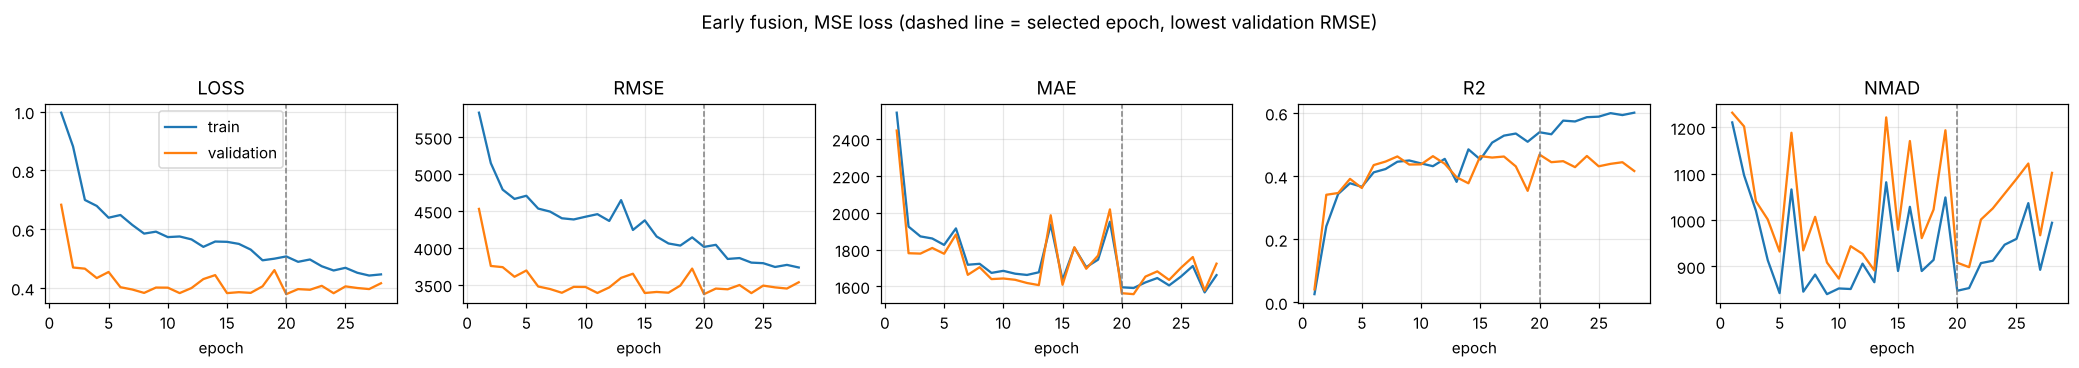

['best_model.pt', 'config.json', 'epoch_001.pt', 'epoch_002.pt', 'epoch_003.pt', 'epoch_004.pt'] ... (32 files)


In [14]:
def plot_history(hist, title):
    fig, axes = plt.subplots(1, 5, figsize=(19, 3.2))
    for ax, m in zip(axes, ["loss", "rmse", "mae", "r2", "nmad"]):
        tr = "train_loss" if m == "loss" else f"train_{m}"
        ax.plot(hist.epoch, hist[tr], label="train"); ax.plot(hist.epoch, hist[f"val_{m}"], label="validation")
        best = hist.loc[hist.val_rmse.idxmin()]
        ax.axvline(best.epoch, color="grey", ls="--", lw=1)
        ax.set_title(m.upper()); ax.set_xlabel("epoch")
    axes[0].legend(); fig.suptitle(title, y=1.03); plt.tight_layout(); plt.show()

plot_history(hist_mse, "Early fusion, MSE loss (dashed line = selected epoch, lowest validation RMSE)")
print(sorted(os.listdir(train_cfg.output_dir))[:6], "...", f"({len(os.listdir(train_cfg.output_dir))} files)")

## 7. Tweedie loss and tuning the power `p`

The loss is the negative Tweedie log-likelihood with a log link (`f = log μ`), on the target divided by its training mean:

$$\ell(y, f) = -\frac{y\,e^{(1-p) f}}{1-p} + \frac{e^{(2-p) f}}{2-p}\qquad(p=1:\ e^f - y f,\quad p=2:\ y e^{-f} + f)$$

Every `p` targets the mean `E[y | x]`; `p` only sets how residuals are weighted (variance ∝ μ^p). It cannot be learned through the loss, so it is tuned on validation over the same grid as notebook 01. For each `p` the selected epoch is the one with the lowest validation RMSE. The table also shows the Gamma deviance (`p = 2`), a relative-error measure that is comparable across all runs.

In [15]:
prep_tw = Preprocessor(N_SPECIAL, group_sizes, target_mode=default_target_mode("tweedie")).fit(train_raw)
train_tw, val_tw = prep_tw.transform(train_raw), prep_tw.transform(val_raw)

P_GRID = [1.2, 1.5, 1.8, 2.0, 2.5]
tweedie_runs = {}
for p in P_GRID:
    cfg_p = TrainConfig(**{**train_cfg.to_dict(), "loss": "tweedie", "tweedie_power": p,
                           "output_dir": str(RUNS / f"tweedie_p{p}"), "verbose": False})
    t = Trainer(model_cfg, cfg_p, prep_tw)
    h = t.fit(train_tw, val_tw)
    best = h.loc[h.val_rmse.idxmin()]
    pred = t.predict(val_tw)
    tweedie_runs[p] = {"best_epoch": int(best.epoch), "epochs_run": len(h), "val_rmse": best.val_rmse,
                       "val_mae": best.val_mae, "val_r2": best.val_r2, "val_nmad": best.val_nmad,
                       "val_gamma_dev": tweedie_deviance(val_raw.y, pred, 2.0), "hist": h}
    print(f"p={p}: best epoch {int(best.epoch):2d}/{len(h)}  val RMSE {best.val_rmse:9.2f}  R2 {best.val_r2:.3f}")

mse_pred = trainer.predict(val_mse)
best_mse = hist_mse.loc[hist_mse.val_rmse.idxmin()]
summary = pd.DataFrame({**{f"tweedie p={p}": {k: v for k, v in r.items() if k != "hist"} for p, r in tweedie_runs.items()},
                        "mse": {"best_epoch": int(best_mse.epoch), "epochs_run": len(hist_mse), "val_rmse": best_mse.val_rmse,
                                "val_mae": best_mse.val_mae, "val_r2": best_mse.val_r2, "val_nmad": best_mse.val_nmad,
                                "val_gamma_dev": tweedie_deviance(val_raw.y, mse_pred, 2.0)}}).T
summary.astype(float).round(4)

p=1.2: best epoch 26/34  val RMSE   3219.60  R2 0.515


p=1.5: best epoch 16/24  val RMSE   3307.34  R2 0.488


p=1.8: best epoch 12/20  val RMSE   3364.05  R2 0.471


p=2.0: best epoch 26/34  val RMSE   3323.59  R2 0.483


p=2.5: best epoch 27/35  val RMSE   3394.17  R2 0.461


,best_epoch,epochs_run,val_rmse,val_mae,val_r2,val_nmad,val_gamma_dev
tweedie p=1.2,26.0,34.0,3219.5975,1573.8786,0.5152,984.8667,0.6527
tweedie p=1.5,16.0,24.0,3307.3428,1567.3028,0.4884,909.2069,0.7475
tweedie p=1.8,12.0,20.0,3364.0522,1611.0791,0.4707,954.1929,0.6695
tweedie p=2.0,26.0,34.0,3323.5947,1596.8676,0.4834,980.2320,0.6536
tweedie p=2.5,27.0,35.0,3394.1654,1644.8066,0.4612,1003.2379,0.6425
mse,20.0,28.0,3371.8850,1563.0235,0.4682,908.0190,0.7928


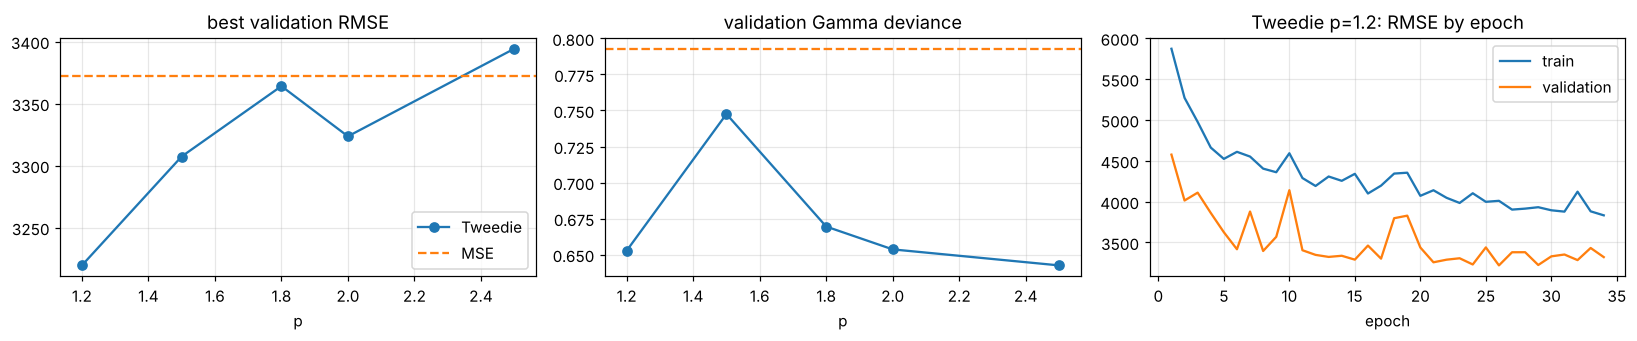

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].plot(P_GRID, summary.loc[[f"tweedie p={p}" for p in P_GRID], "val_rmse"], "o-", label="Tweedie")
ax[0].axhline(best_mse.val_rmse, color="C1", ls="--", label="MSE"); ax[0].set_xlabel("p"); ax[0].set_title("best validation RMSE"); ax[0].legend()
ax[1].plot(P_GRID, summary.loc[[f"tweedie p={p}" for p in P_GRID], "val_gamma_dev"], "o-")
ax[1].axhline(summary.loc["mse", "val_gamma_dev"], color="C1", ls="--"); ax[1].set_xlabel("p"); ax[1].set_title("validation Gamma deviance")
best_p = min(tweedie_runs, key=lambda p: tweedie_runs[p]["val_rmse"])
h = tweedie_runs[best_p]["hist"]
ax[2].plot(h.epoch, h.train_rmse, label="train"); ax[2].plot(h.epoch, h.val_rmse, label="validation")
ax[2].set_title(f"Tweedie p={best_p}: RMSE by epoch"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

**What this run shows (synthetic data, one seed per setting):** here `p = 1.2` is selected, with validation RMSE ≈ 3,220 and R² 0.52, against 3,372 and R² 0.47 for MSE.

* Every Tweedie model has a lower Gamma deviance than MSE (0.64–0.75 against 0.79). It is more accurate *relative to the size* of the target.
* On RMSE the picture is mixed: `p = 2.5` is slightly worse than MSE.
* Notebook 01 selected `p = 1.5` for the late-fusion model. When the best power moves like this between two very similar models, the differences between powers are at the level of noise. On your data, tune `p` over several seeds.

## 8. Reload the selected model and evaluate

The overall winner across MSE and all Tweedie powers is chosen by validation RMSE. `load_checkpoint` rebuilds the model and the fitted preprocessor from `best_model.pt`, and the checkpoint records `missing_fusion="early"`, so nothing else needs configuring.

In [17]:
candidates = {"mse": (best_mse.val_rmse, RUNS / "mse")}
candidates.update({f"tweedie p={p}": (r["val_rmse"], RUNS / f"tweedie_p{p}") for p, r in tweedie_runs.items()})
winner = min(candidates, key=lambda k: candidates[k][0])
print("selected:", winner, "| validation RMSE", round(candidates[winner][0], 3))

model_best, prep_best, cfg_best, ckpt = load_checkpoint(str(candidates[winner][1] / "best_model.pt"), device="cpu")
print("missing_fusion in checkpoint:", ckpt["model_config"]["missing_fusion"])
val_pred = predict_with(model_best, prep_best, cfg_best, prep_best.transform(val_raw))
print("epoch", ckpt["epoch"], "| recomputed:", {k: round(v, 4) for k, v in regression_metrics(val_raw.y, val_pred).items()})

selected: tweedie p=1.2 | validation RMSE 3219.597
missing_fusion in checkpoint: early


epoch 26 | recomputed: {'rmse': 3219.5975, 'mae': 1573.8786, 'r2': 0.5152, 'nmad': 984.8667}


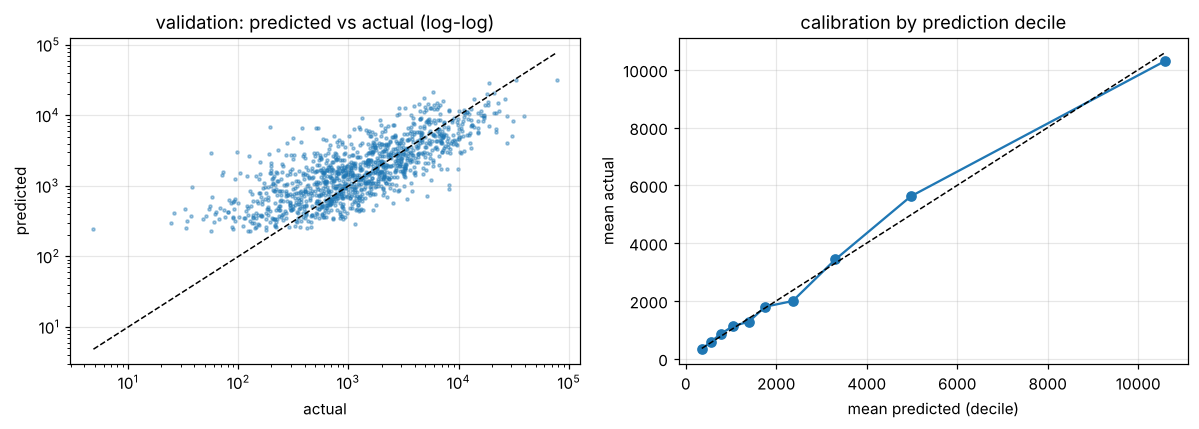

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(val_raw.y, val_pred, s=4, alpha=0.4)
lim = [min(val_raw.y.min(), val_pred.min()), max(val_raw.y.max(), val_pred.max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("actual"); ax[0].set_ylabel("predicted"); ax[0].set_title("validation: predicted vs actual (log-log)")
dec = pd.qcut(val_pred, 10, labels=False)
cal = pd.DataFrame({"pred": val_pred, "y": val_raw.y, "dec": dec}).groupby("dec").mean()
ax[1].plot(cal.pred, cal.y, "o-"); ax[1].plot(cal.pred, cal.pred, "k--", lw=1)
ax[1].set_xlabel("mean predicted (decile)"); ax[1].set_ylabel("mean actual"); ax[1].set_title("calibration by prediction decile")
plt.tight_layout(); plt.show()

## 9. What the model learned about missing and special values

With early fusion there is no dedicated missingness CLS to inspect, but the **state embeddings** `E_state` (one vector per state, shared by all variables) can be read directly.

* **Cosine similarity between states.** Two special codes with very similar vectors are treated almost interchangeably. A code close to "missing" is treated like a missing value.
* **Prediction sensitivity.** For each state, take the validation cells that are *regular*, pretend they had that state, and measure how much the predictions move. This is a counterfactual probe of how much the model relies on each code. It reflects the model, not causality in the data.

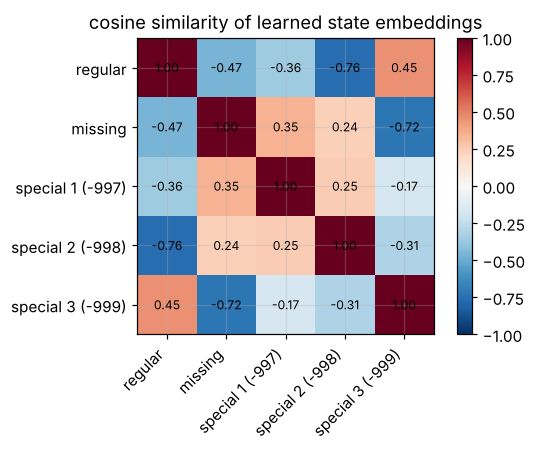

,regular,missing,special 1 (-997),special 2 (-998),special 3 (-999)
embedding norm,0.108,0.151,0.169,0.193,0.135


In [19]:
E = model_best.value_embed.state_emb.weight.detach()
state_names = [names[i] for i in range(E.shape[0])]
cos = torch.nn.functional.cosine_similarity(E[:, None, :], E[None, :, :], dim=-1).numpy()

fig, ax = plt.subplots(figsize=(5.5, 4.2))
im = ax.imshow(cos, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(state_names)), state_names, rotation=45, ha="right"); ax.set_yticks(range(len(state_names)), state_names)
for i in range(len(state_names)):
    for j in range(len(state_names)):
        ax.text(j, i, f"{cos[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("cosine similarity of learned state embeddings"); plt.colorbar(im); plt.tight_layout(); plt.show()
pd.Series(E.norm(dim=1).numpy(), index=state_names, name="embedding norm").round(3).to_frame().T

In [20]:
val_proc = prep_best.transform(val_raw)
rng = np.random.default_rng(0)
reg_idx = np.argwhere(val_proc.state.numpy() == 0)
pick = reg_idx[rng.choice(len(reg_idx), size=min(400, len(reg_idx)), replace=False)]   # (record, t, v) cells

def predict_state_override(code):
    st = val_proc.state.clone()
    st[pick[:, 0], pick[:, 1], pick[:, 2]] = code
    d = type(val_proc)(val_proc.x, st, val_proc.snapshot, val_proc.y, val_proc.y_raw)
    return predict_with(model_best, prep_best, cfg_best, d)

base = predict_with(model_best, prep_best, cfg_best, val_proc)
touched = np.unique(pick[:, 0])
sens = {names[c]: 100 * (predict_state_override(c)[touched].mean() / base[touched].mean() - 1)
        for c in range(1, 2 + N_SPECIAL)}
print(f"{len(pick)} regular cells in {len(touched)} validation records switched to each state")
pd.Series(sens, name="change in mean prediction of those records (%)").round(2).to_frame().T

400 regular cells in 339 validation records switched to each state


,missing,special 1 (-997),special 2 (-998),special 3 (-999)
change in mean prediction of those records (%),0.41,0.12,0.56,-0.41


**Reading the two views.**

* **Probe.** Each number is the change in the mean prediction of the affected records when, on average, one of their 88 cells switches from regular to that state. That is why the effects are small.
* **What the generator does.** The share of *special 2* cells raises the target directly, and riskier records have more random *gaps* (missing cells). Special codes 1 and 3 have no effect of their own.
* **What the model learned:**
  * *special 2* raises predictions the most and *missing* comes next, consistent with the generator;
  * in the similarity map, *missing*, *special 1* and *special 2* sit together, opposite *regular*;
  * *special 3* lowers predictions by about as much as *missing* raises them, and its embedding sits closer to *regular*, although the generator gives it no effect.
* **Why special 3 matters.** It covers under 1% of cells (0.85%), and **rare codes get noisy embeddings**. That is worth checking for rare special values in your data, for example by merging very rare codes or adding more regularisation.

Use these two views to confirm that each code's learned effect matches its business meaning. Probes like this describe the model, not causal effects in the data.

In [21]:
def best_row(run_dir):
    h = pd.read_csv(run_dir / "metrics.csv")
    b = h.loc[h.val_rmse.idxmin()]
    return {"val_rmse": b.val_rmse, "val_mae": b.val_mae, "val_r2": b.val_r2, "val_nmad": b.val_nmad,
            "best_epoch": int(b.epoch), "sec_per_epoch": h.epoch_time_s.mean()}

run_names = ["mse"] + [f"tweedie_p{p}" for p in P_GRID]
rows = {}
for r in run_names:
    rows[("early", r)] = best_row(RUNS / r)
    if (LATE_RUNS / r / "metrics.csv").exists():
        rows[("late", r)] = best_row(LATE_RUNS / r)
cmp = pd.DataFrame(rows).T
cmp.index.names = ["fusion", "run"]
if "late" in cmp.index.get_level_values(0):
    wide = cmp["val_rmse"].unstack(0)
    wide["early - late"] = wide["early"] - wide["late"]
    display(cmp.astype(float).round(3).sort_index(level=1))
    print("validation RMSE at the selected epoch:")
    display(wide.round(1))
else:
    print("notebook 01 runs not found - showing early fusion only")
    display(cmp.astype(float).round(3))

,,val_rmse,val_mae,val_r2,val_nmad,best_epoch,sec_per_epoch
fusion,run,,,,,,
early,mse,3371.885,1563.024,0.468,908.019,20.0,6.691
late,mse,3392.988,1626.212,0.462,921.757,10.0,9.539
early,tweedie_p1.2,3219.597,1573.879,0.515,984.867,26.0,6.619
late,tweedie_p1.2,3276.173,1569.136,0.498,950.453,26.0,9.150
early,tweedie_p1.5,3307.343,1567.303,0.488,909.207,16.0,6.171
late,tweedie_p1.5,3200.700,1551.426,0.521,970.797,30.0,9.459
early,tweedie_p1.8,3364.052,1611.079,0.471,954.193,12.0,6.391
late,tweedie_p1.8,3331.652,1560.467,0.481,911.992,21.0,9.191
early,tweedie_p2.0,3323.595,1596.868,0.483,980.232,26.0,6.186


validation RMSE at the selected epoch:


fusion,early,late,early - late
run,,,
mse,3371.9,3393.0,-21.1
tweedie_p1.2,3219.6,3276.2,-56.6
tweedie_p1.5,3307.3,3200.7,106.6
tweedie_p1.8,3364.1,3331.7,32.4
tweedie_p2.0,3323.6,3275.1,48.5
tweedie_p2.5,3394.2,3298.9,95.3


**What the comparison shows (one seed per configuration):**

* **No uniform winner on this synthetic data.**
  * Early fusion has the lower validation RMSE with MSE and with Tweedie `p = 1.2`; late fusion is lower for `p = 1.5`–`2.5`.
  * The best run of each design differs by about 20 RMSE (late `p = 1.5`: 3,201; early `p = 1.2`: 3,220).
  * That gap is far below the seed-to-seed standard deviation of 18–130 RMSE measured in notebook 02.
* **Early fusion is consistently cheaper:** 28% fewer parameters and about 30% less time per epoch (≈6.3 s against ≈9.1 s here, on the same CPU setting).
* **Why the designs tie here:** the synthetic target uses missingness only through a few simple effects, so there is little *context-dependent* missing/special signal for token-level fusion to exploit. Real data with informative special codes (for example "account closed" after a falling balance) is where the difference can show.
* **Decide on your data** with the multi-seed loop in notebook 02, select on validation, and confirm on an untouched test set. With equal accuracy, the cheaper model is the better default.

## 11. Checklist for your data

1. **Alignment.** Build `x`, `missing`, `special`, `snapshot` and `y` with the *same* `record_ids` order.
2. **Codes.** Set `n_special_codes = K`; special codes are 1..K and 0 means "not special".
3. **PLE groups.** Build the snapshot matrix with the column order returned by `group_columns_by_prefix`, and use its group sizes.
4. **`state_emb_dim`** is the width of each cell vector. A patch token is a projection of `patch_len × state_emb_dim` numbers, so 8–32 is plenty for a handful of states.
5. **`patch_len=1`.** One token per cell is affordable with T = 11. It gives attention the finest view of where missing or special cells sit, at the cost of 11 instead of 9 tokens per variable.
6. **Size.** There is one grid of `(V+1)·(Np+1)` tokens per record. That is half the attention cost of late fusion, but it still grows with V. For hundreds of variables, use `gradient_checkpointing`, a larger stride or a smaller batch.
7. **Choosing between designs.** Compare early and late fusion on your data with several seeds (notebook 02 has the loop), select on validation, and report on an untouched test set.